#### Imports

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

In [2]:
df = pd.read_csv("Delivery_Data.csv")

df

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68
...,...,...,...,...,...,...,...,...,...
995,107,8.50,Clear,High,Evening,Car,13,3.0,54
996,271,16.28,Rainy,Low,Morning,Scooter,8,9.0,71
997,861,15.62,Snowy,High,Evening,Scooter,26,2.0,81
998,436,14.17,Clear,Low,Afternoon,Bike,8,0.0,55


#### Finding Missing Values


In [3]:
df.isna().sum()

Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64

In [4]:
df.dtypes

Order_ID                    int64
Distance_km               float64
Weather                       str
Traffic_Level                 str
Time_of_Day                   str
Vehicle_Type                  str
Preparation_Time_min        int64
Courier_Experience_yrs    float64
Delivery_Time_min           int64
dtype: object

#### Filling Categorical Columns With NULL Values

In [5]:
col = ['Weather', 'Traffic_Level', 'Time_of_Day']

df[col] = df[col].fillna(df[col].mode().iloc[0])

df.isna().sum()

Order_ID                   0
Distance_km                0
Weather                    0
Traffic_Level              0
Time_of_Day                0
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64

#### Filling Numerical Columns With NULL Values

In [6]:
df['Courier_Experience_yrs']  = df['Courier_Experience_yrs'].fillna(df['Courier_Experience_yrs'].mean())

df.isna().sum()

Order_ID                  0
Distance_km               0
Weather                   0
Traffic_Level             0
Time_of_Day               0
Vehicle_Type              0
Preparation_Time_min      0
Courier_Experience_yrs    0
Delivery_Time_min         0
dtype: int64

In [7]:
df = df.drop(columns = 'Order_ID')

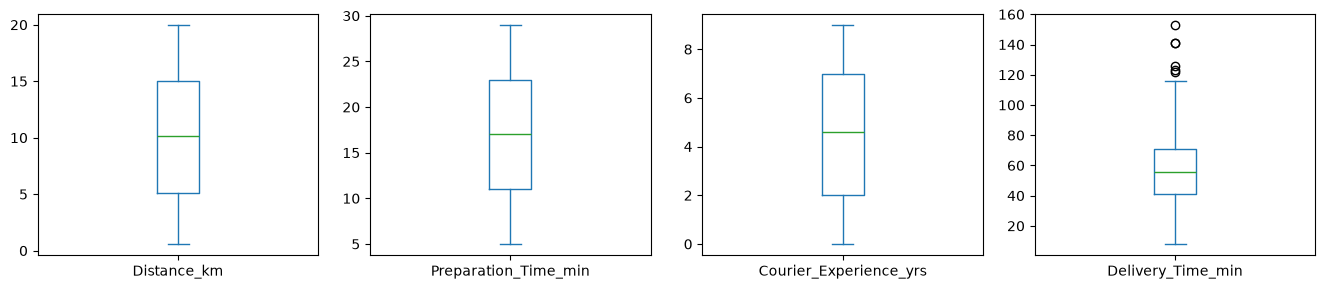

In [8]:
df.plot(kind="box",subplots=True,layout=(1,6),figsize=(20,3))
plt.tight_layout()

In [9]:
df['Delivery_Time_min'].describe()

count    1000.000000
mean       56.732000
std        22.070915
min         8.000000
25%        41.000000
50%        55.500000
75%        71.000000
max       153.000000
Name: Delivery_Time_min, dtype: float64

In [10]:
q1 = 41.0
q3 = 71.0

iqr = q3 - q1

minimum = q1 - (1.5 * iqr)
maximum = q3 + (1.5 * iqr)

print(f"Minimum IQR value : {minimum}")
print(f"Maximum IQR value : {maximum}")

Minimum IQR value : -4.0
Maximum IQR value : 116.0


In [11]:
df = df[
    (df['Delivery_Time_min'] > minimum)&
    (df['Delivery_Time_min'] < maximum)
]

<Axes: >

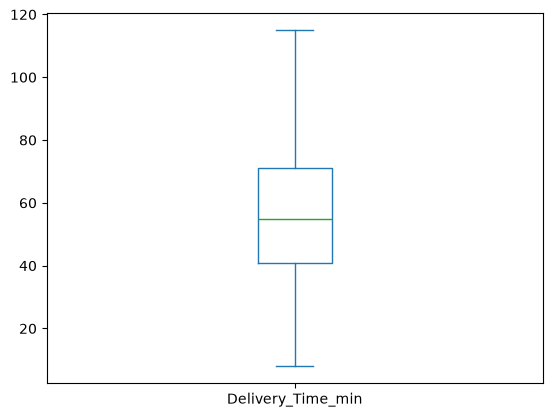

In [12]:
df['Delivery_Time_min'].plot(kind="box")

In [13]:
col = ['Weather','Traffic_Level','Time_of_Day','Vehicle_Type']

df[col] = df[col].astype('category')

df.dtypes

Distance_km                float64
Weather                   category
Traffic_Level             category
Time_of_Day               category
Vehicle_Type              category
Preparation_Time_min         int64
Courier_Experience_yrs     float64
Delivery_Time_min            int64
dtype: object

In [14]:
for col in col:
    print(df[col].unique())

['Windy', 'Clear', 'Foggy', 'Rainy', 'Snowy']
Categories (5, str): ['Clear', 'Foggy', 'Rainy', 'Snowy', 'Windy']
['Low', 'Medium', 'High']
Categories (3, str): ['High', 'Low', 'Medium']
['Afternoon', 'Evening', 'Night', 'Morning']
Categories (4, str): ['Afternoon', 'Evening', 'Morning', 'Night']
['Scooter', 'Bike', 'Car']
Categories (3, str): ['Bike', 'Car', 'Scooter']


In [15]:
ord_col = ['Traffic_Level']
nom_col = ['Weather','Time_of_Day','Vehicle_Type']



ValueError: Expected a 2-dimensional container but got <class 'pandas.Series'> instead. Pass a DataFrame containing a single row (i.e. single sample) or a single column (i.e. single feature) instead.